In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
top_n = 10

## Anti-Aliasing

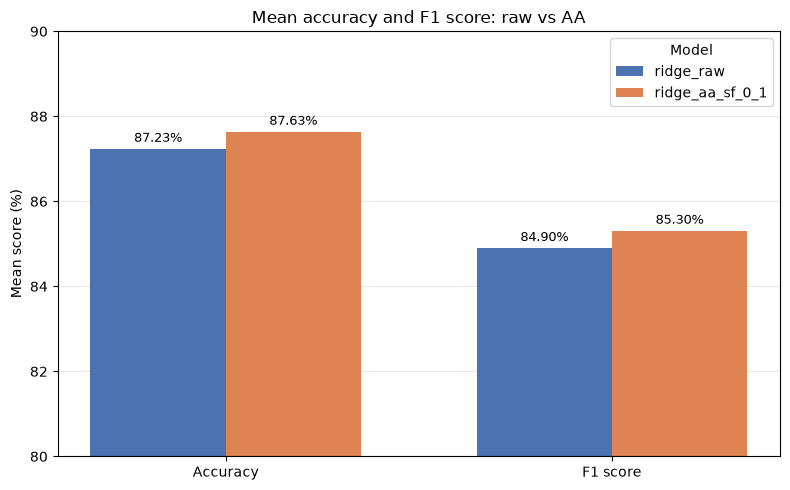

In [6]:
df = pd.read_csv("../results_improvements/aa_summary.csv")

means = {
    "Accuracy": [df["ridge_raw"].mean() * 100, df["ridge_aa_sf_0_1"].mean() * 100],
    "F1 score": [df["ridge_raw_f1"].mean() * 100, df["ridge_aa_sf_0_1_f1"].mean() * 100],
}
models = ["ridge_raw", "ridge_aa_sf_0_1"]
colors = ["#4C72B0", "#DD8452"]

metrics = list(means.keys())
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

for i, (model, color) in enumerate(zip(models, colors)):
    values = [means[m][i] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=model, color=color)
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Mean score (%)")
ax.set_title(f"Mean accuracy and F1 score: raw vs AA")
ax.set_ylim(80, 90)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

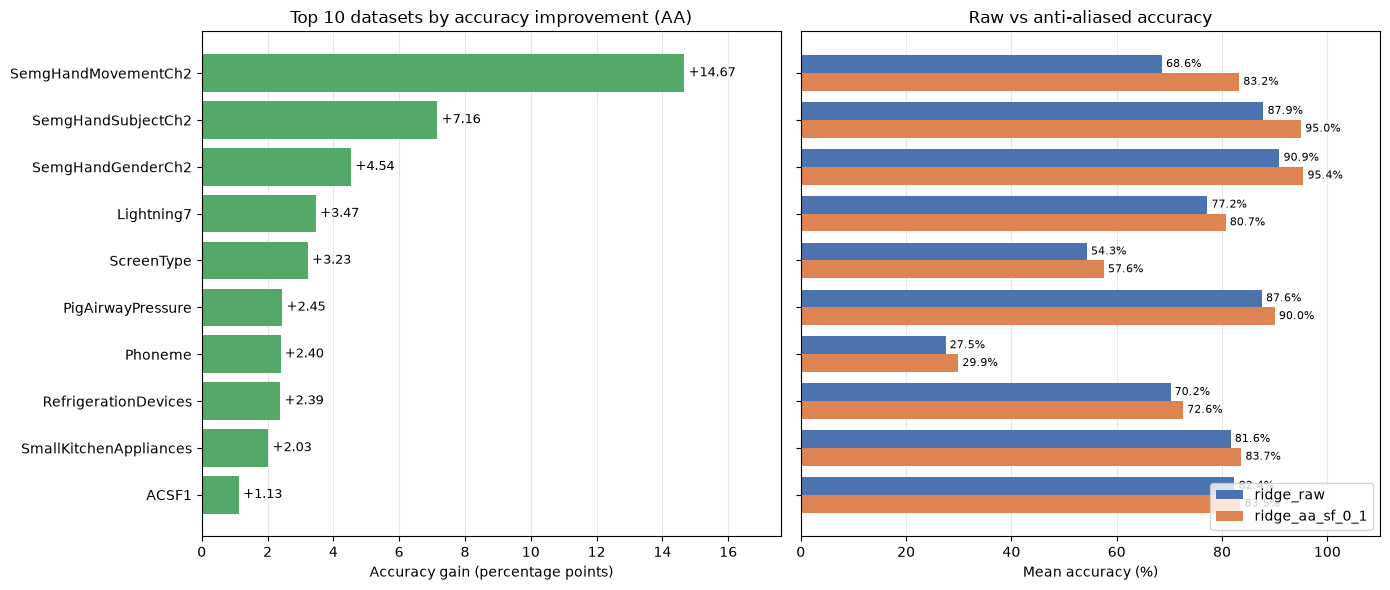

In [5]:
top = df.nlargest(top_n, "ridge_aa_sf_0_1_minus_raw").iloc[::-1].copy()
top[["ridge_raw", "ridge_aa_sf_0_1", "ridge_aa_sf_0_1_minus_raw"]] *= 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

bars = ax1.barh(top["dataset"], top["ridge_aa_sf_0_1_minus_raw"], color="#55A868")
ax1.bar_label(bars, fmt="+%.2f", padding=3, fontsize=9)
ax1.set_xlabel("Accuracy gain (percentage points)")
ax1.set_title(f"Top {top_n} datasets by accuracy improvement (AA)")
ax1.set_xlim(0, top["ridge_aa_sf_0_1_minus_raw"].max() * 1.2)
ax1.grid(axis="x", alpha=0.3)
ax1.set_axisbelow(True)

y = np.arange(len(top))
height = 0.38
b_raw = ax2.barh(y + height / 2, top["ridge_raw"], height, label="ridge_raw", color="#4C72B0")
b_aa = ax2.barh(y - height / 2, top["ridge_aa_sf_0_1"], height, label="ridge_aa_sf_0_1", color="#DD8452")
ax2.bar_label(b_raw, fmt="%.1f%%", padding=3, fontsize=8)
ax2.bar_label(b_aa, fmt="%.1f%%", padding=3, fontsize=8)
ax2.set_xlabel("Mean accuracy (%)")
ax2.set_title("Raw vs anti-aliased accuracy")
ax2.set_xlim(0, 110)
ax2.legend(loc="lower right")
ax2.grid(axis="x", alpha=0.3)
ax2.set_axisbelow(True)

plt.tight_layout()
plt.show()

## POC (Co-Activation Pooling)

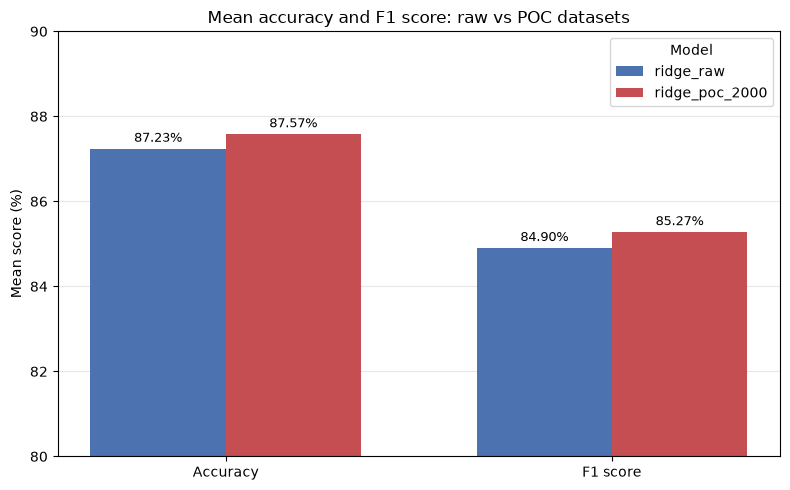

In [7]:
df_poc = pd.read_csv("../results_improvements/poc_summary.csv")

means = {
    "Accuracy": [df_poc["ridge_raw"].mean() * 100, df_poc["ridge_poc_2000"].mean() * 100],
    "F1 score": [df_poc["ridge_raw_f1"].mean() * 100, df_poc["ridge_poc_2000_f1"].mean() * 100],
}
models = ["ridge_raw", "ridge_poc_2000"]
colors = ["#4C72B0", "#C44E52"]

metrics = list(means.keys())
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

for i, (model, color) in enumerate(zip(models, colors)):
    values = [means[m][i] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=model, color=color)
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Mean score (%)")
ax.set_title(f"Mean accuracy and F1 score: raw vs POC datasets")
ax.set_ylim(80, 90)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

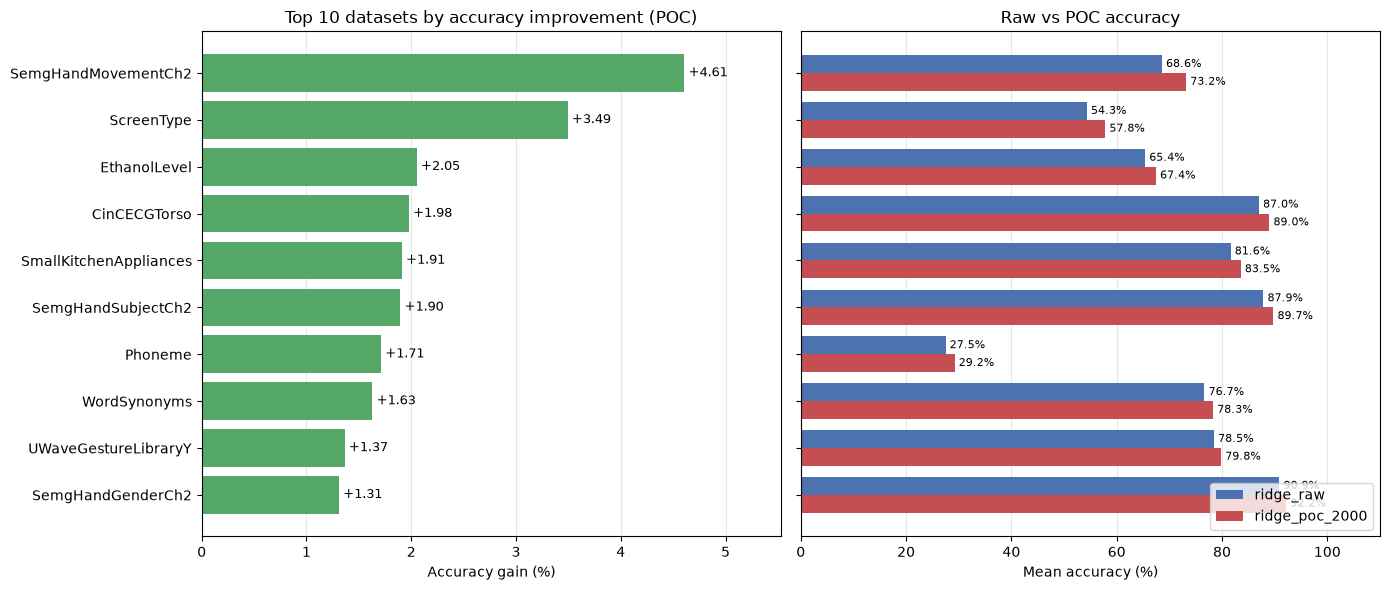

In [8]:
top = df_poc.nlargest(top_n, "ridge_poc_2000_minus_raw").iloc[::-1].copy()
top[["ridge_raw", "ridge_poc_2000", "ridge_poc_2000_minus_raw"]] *= 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

bars = ax1.barh(top["dataset"], top["ridge_poc_2000_minus_raw"], color="#55A868")
ax1.bar_label(bars, fmt="+%.2f", padding=3, fontsize=9)
ax1.set_xlabel("Accuracy gain (%)")
ax1.set_title(f"Top {top_n} datasets by accuracy improvement (POC)")
ax1.set_xlim(0, top["ridge_poc_2000_minus_raw"].max() * 1.2)
ax1.grid(axis="x", alpha=0.3)
ax1.set_axisbelow(True)

y = np.arange(len(top))
height = 0.38
b_raw = ax2.barh(y + height / 2, top["ridge_raw"], height, label="ridge_raw", color="#4C72B0")
b_poc = ax2.barh(y - height / 2, top["ridge_poc_2000"], height, label="ridge_poc_2000", color="#C44E52")
ax2.bar_label(b_raw, fmt="%.1f%%", padding=3, fontsize=8)
ax2.bar_label(b_poc, fmt="%.1f%%", padding=3, fontsize=8)
ax2.set_xlabel("Mean accuracy (%)")
ax2.set_title("Raw vs POC accuracy")
ax2.set_xlim(0, 110)
ax2.legend(loc="lower right")
ax2.grid(axis="x", alpha=0.3)
ax2.set_axisbelow(True)

plt.tight_layout()
plt.show()